# Analyse des colonnes des données de dimensionnement

Ce notebook dresse un profil des deux jeux de données d'entrée du projet : structure, types, complétude, valeurs distinctes, distributions et relations entre les variables. Il permet de repérer rapidement les colonnes incomplètes, les valeurs atypiques et les corrélations avant la classification ou la prédiction.

Les graphiques sont construits automatiquement à partir des colonnes présentes dans les CSV de `data/imported/`.

In [1]:
# À exécuter une seule fois si nécessaire.
# %pip install -r requirements.txt

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


def find_project_root() -> Path:
    cwd = Path.cwd().resolve()
    for candidate in (cwd, cwd / 'resort_sizing', cwd.parent):
        if (candidate / 'notebooks').is_dir() and (candidate / 'data').is_dir():
            return candidate
    raise RuntimeError(
        'Lancez ce notebook depuis SkiJo, resort_sizing ou resort_sizing/notebooks.'
    )


PROJECT_ROOT = find_project_root()
DATA_PATHS = {
    'Classification': PROJECT_ROOT / 'data' / 'imported' / 'classification_features.csv',
    'Prédiction': PROJECT_ROOT / 'data' / 'imported' / 'prediction_features.csv',
}
missing_files = [str(path.relative_to(PROJECT_ROOT)) for path in DATA_PATHS.values() if not path.exists()]
if missing_files:
    raise FileNotFoundError(f"Fichiers de données absents : {', '.join(missing_files)}")

datasets = {name: pd.read_csv(path) for name, path in DATA_PATHS.items()}
sns.set_theme(style='whitegrid', context='notebook')
COLORS = {'Classification': '#4E79A7', 'Prédiction': '#F28E2B'}

## Vue d'ensemble

Le tableau résume le volume, le nombre de colonnes et les éventuels doublons d'identifiant. Les aperçus qui suivent permettent de vérifier le contenu brut.

In [3]:
overview = pd.DataFrame([
    {
        'jeu': name,
        'lignes': len(data),
        'colonnes': data.shape[1],
        'cellules_manquantes': int(data.isna().sum().sum()),
        'lignes_dupliquees': int(data.duplicated().sum()),
        'slugs_dupliques': int(data['slug'].duplicated().sum()) if 'slug' in data else pd.NA,
    }
    for name, data in datasets.items()
]).set_index('jeu')
display(overview)

for name, data in datasets.items():
    print(f'\n{name} — {DATA_PATHS[name].relative_to(PROJECT_ROOT)}')
    display(data.head())

,lignes,colonnes,cellules_manquantes,lignes_dupliquees,slugs_dupliques
jeu,,,,,
Classification,199,7,3,0,0
Prédiction,319,8,187,0,0



Classification — data/imported/classification_features.csv


,station,slug,season,pistes_km,remontees_longueur_km,remontees_denivele_m,remontees_debit_pers_h
0,Abondance,abondance,2026-27,15.0,6.603,1653.0,6195.0
1,Abriès,abries-queyras,2026-27,33.0,6.445,1954.0,5500.0
2,Aiguilles,aiguilles,2026-27,3.0,0.243,23.0,500.0
3,Aillon-le-Jeune,aillon-le-jeune,2026-27,8.0,2.538,608.0,3895.0
4,Aillons-Margériaz,aillons-margeriaz,2026-27,24.0,10.203,2075.0,8550.0



Prédiction — data/imported/prediction_features.csv


,station,slug,season,denivele_station_m,pistes_km,pistes_count,remontees_count,source_remontees_count
0,Abondance,abondance,2026-27,1508.0,15.0,13.0,8.0,détail hors tapis
1,Abriès,abries-queyras,2026-27,900.0,33.0,16.0,7.0,détail hors tapis
2,Aiguille du Midi (Chamonix),aiguille-du-midi-chamonix,2026-27,2807.0,NaN,NaN,5.0,détail hors tapis
3,Aiguilles,aiguilles,2026-27,160.0,3.0,5.0,1.0,détail hors tapis
4,Aillon-le-Jeune,aillon-le-jeune,2026-27,312.0,8.0,NaN,5.0,détail hors tapis


## Schéma et qualité de chaque colonne

Pour chaque colonne, ce profil indique le type détecté, la complétude, la cardinalité et, pour les valeurs numériques, les bornes et la médiane.

In [4]:
def column_profile(data: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for column in data.columns:
        values = data[column]
        numeric = pd.api.types.is_numeric_dtype(values)
        rows.append({
            'colonne': column,
            'type': str(values.dtype),
            'renseignées': int(values.notna().sum()),
            'manquantes': int(values.isna().sum()),
            'complétude_%': round(values.notna().mean() * 100, 1),
            'valeurs_distinctes': int(values.nunique(dropna=True)),
            'minimum': values.min() if numeric and values.notna().any() else pd.NA,
            'médiane': values.median() if numeric and values.notna().any() else pd.NA,
            'maximum': values.max() if numeric and values.notna().any() else pd.NA,
        })
    return pd.DataFrame(rows).set_index('colonne')


profiles = {name: column_profile(data) for name, data in datasets.items()}
for name, profile in profiles.items():
    print(f'\n{name}')
    display(profile)


Classification


,type,renseignées,manquantes,complétude_%,valeurs_distinctes,minimum,médiane,maximum
colonne,,,,,,,,
station,str,199,0,100.0,199,<NA>,<NA>,<NA>
slug,str,199,0,100.0,199,<NA>,<NA>,<NA>
season,str,199,0,100.0,1,<NA>,<NA>,<NA>
pistes_km,float64,199,0,100.0,99,0.5,12.0,250.0
remontees_longueur_km,float64,198,1,99.5,195,0.123,3.723,65.748
remontees_denivele_m,float64,198,1,99.5,190,9.0,899.5,15914.0
remontees_debit_pers_h,float64,198,1,99.5,187,500.0,4942.5,131867.0



Prédiction


,type,renseignées,manquantes,complétude_%,valeurs_distinctes,minimum,médiane,maximum
colonne,,,,,,,,
station,str,319,0,100.0,318,<NA>,<NA>,<NA>
slug,str,319,0,100.0,319,<NA>,<NA>,<NA>
season,str,319,0,100.0,1,<NA>,<NA>,<NA>
denivele_station_m,float64,285,34,89.3,178,41.0,600.0,2807.0
pistes_km,float64,281,38,88.1,125,0.3,22.0,445.0
pistes_count,float64,243,76,76.2,85,1.0,21.0,320.0
remontees_count,float64,280,39,87.8,54,1.0,8.0,109.0
source_remontees_count,str,319,0,100.0,2,<NA>,<NA>,<NA>


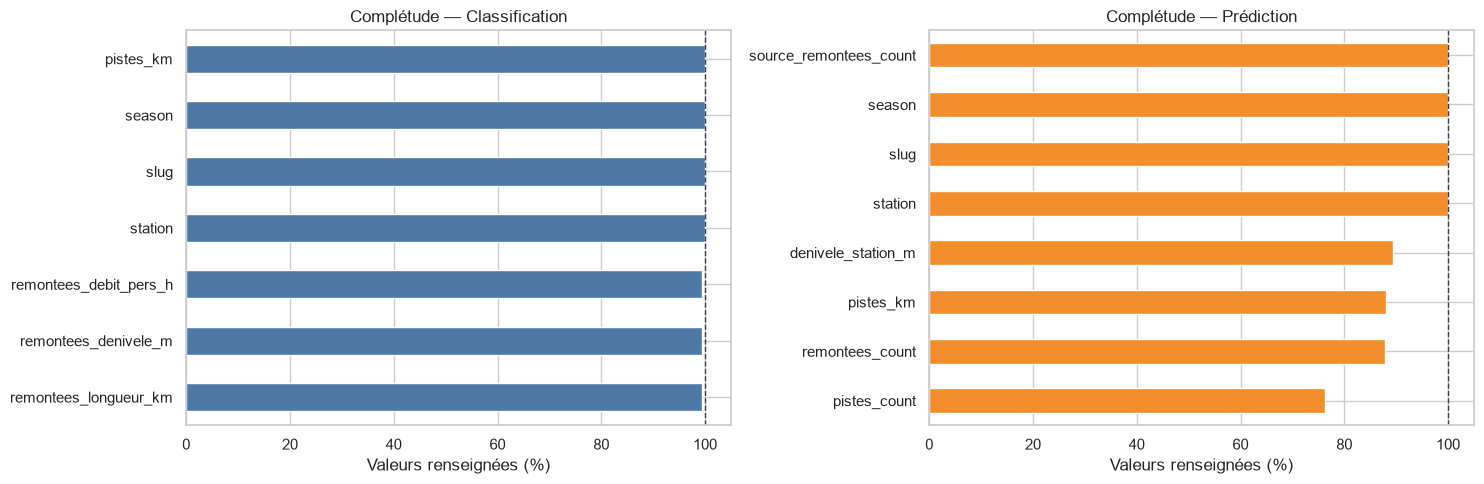

In [5]:
fig, axes = plt.subplots(1, len(profiles), figsize=(15, 5), squeeze=False)
for ax, (name, profile) in zip(axes.flat, profiles.items()):
    completeness = profile['complétude_%'].sort_values()
    completeness.plot.barh(ax=ax, color=COLORS[name])
    ax.axvline(100, color='#374151', linestyle='--', linewidth=1)
    ax.set(title=f'Complétude — {name}', xlabel='Valeurs renseignées (%)', ylabel='')
    ax.set_xlim(0, 105)
plt.tight_layout()
plt.show()

## Distribution des colonnes numériques

Les histogrammes montrent la forme des distributions. Les boîtes à moustaches complètent la lecture en mettant en évidence la médiane, la dispersion et les valeurs éloignées.

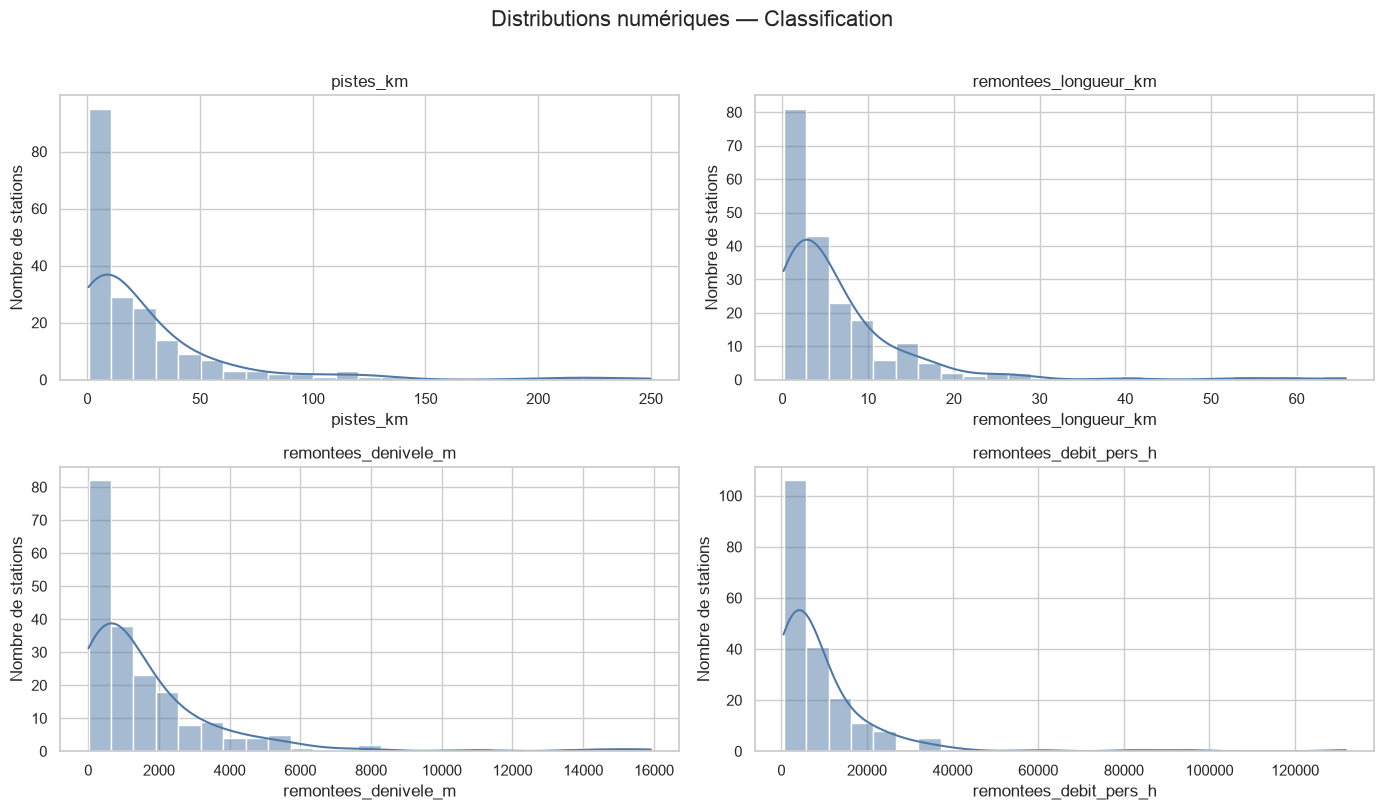

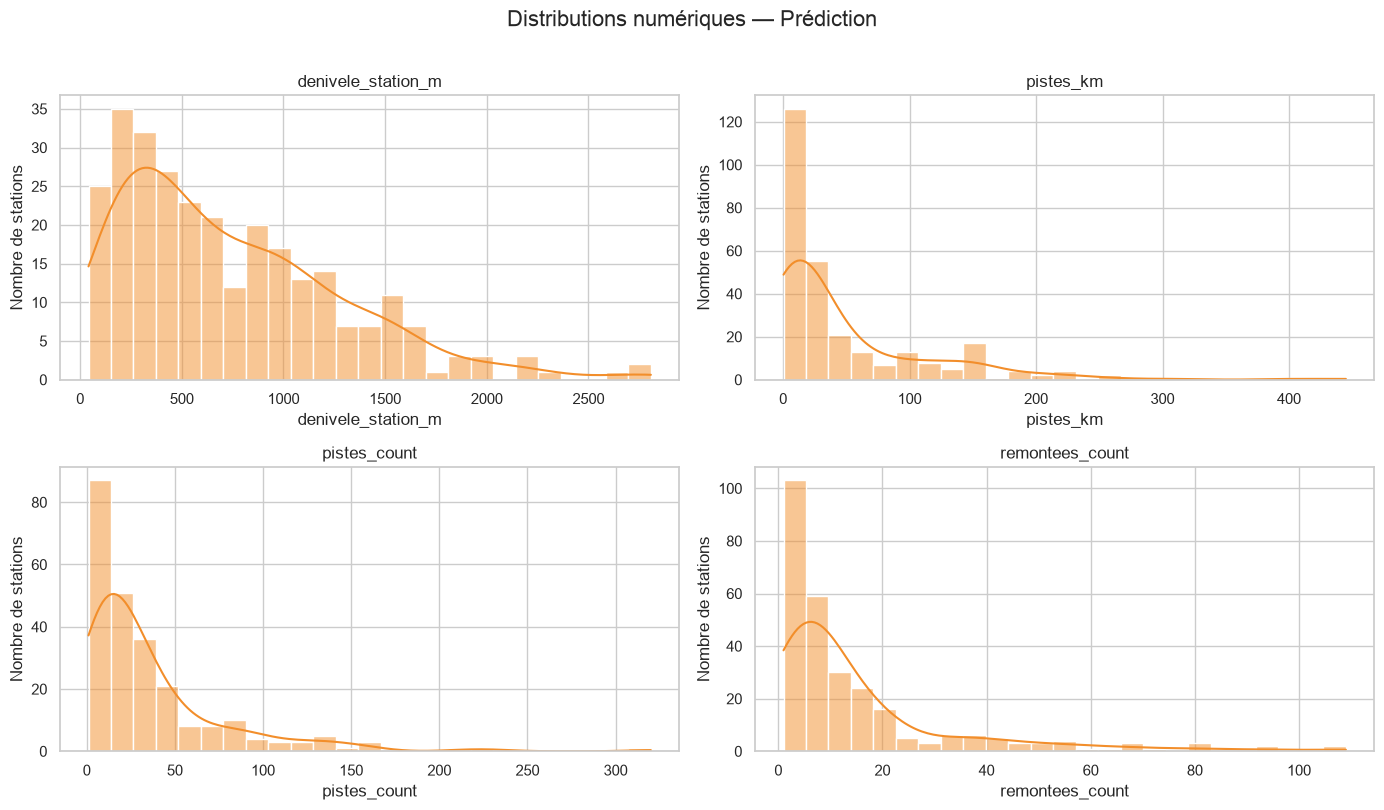

In [6]:
for name, data in datasets.items():
    numeric_columns = data.select_dtypes(include='number').columns.tolist()
    ncols = 2
    nrows = int(np.ceil(len(numeric_columns) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4 * nrows), squeeze=False)
    for ax, column in zip(axes.flat, numeric_columns):
        sns.histplot(data=data, x=column, bins=25, kde=True, color=COLORS[name], ax=ax)
        ax.set(title=column, ylabel='Nombre de stations')
    for ax in axes.flat[len(numeric_columns):]:
        ax.set_visible(False)
    fig.suptitle(f'Distributions numériques — {name}', fontsize=16, y=1.01)
    plt.tight_layout()
    plt.show()

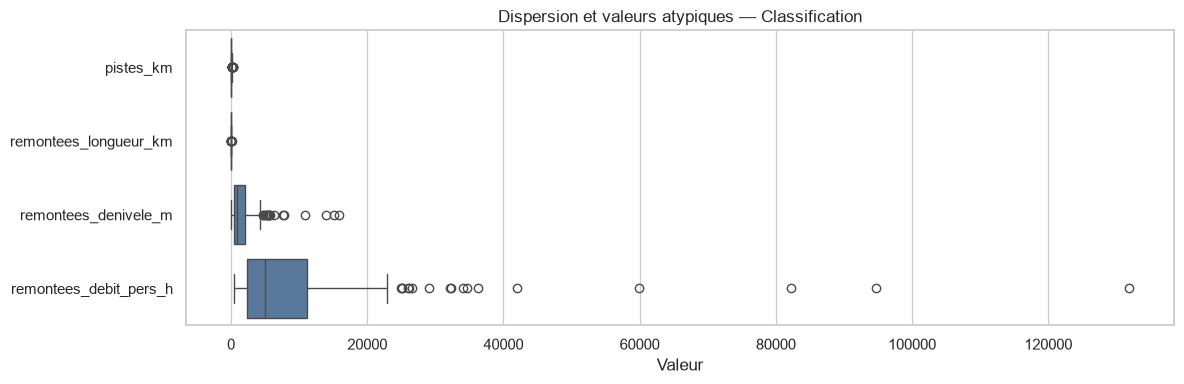

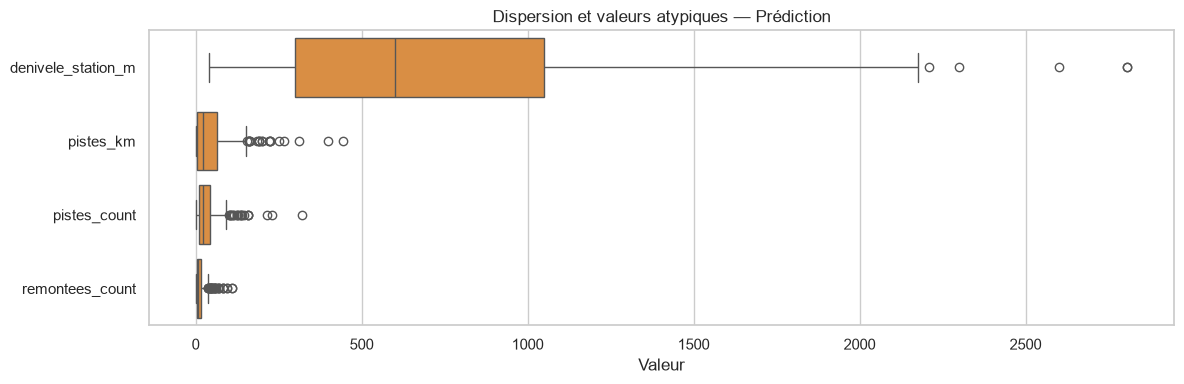

In [7]:
for name, data in datasets.items():
    numeric_columns = data.select_dtypes(include='number').columns.tolist()
    long_data = data[numeric_columns].melt(var_name='colonne', value_name='valeur')
    fig, ax = plt.subplots(figsize=(12, max(4, len(numeric_columns) * 0.8)))
    sns.boxplot(data=long_data, x='valeur', y='colonne', color=COLORS[name], ax=ax)
    ax.set(title=f'Dispersion et valeurs atypiques — {name}', xlabel='Valeur', ylabel='')
    plt.tight_layout()
    plt.show()

## Corrélations et relations entre indicateurs

La matrice de corrélation mesure les relations linéaires entre colonnes numériques. Les diagrammes de dispersion centrés sur les kilomètres de pistes montrent aussi la forme réelle de ces relations.

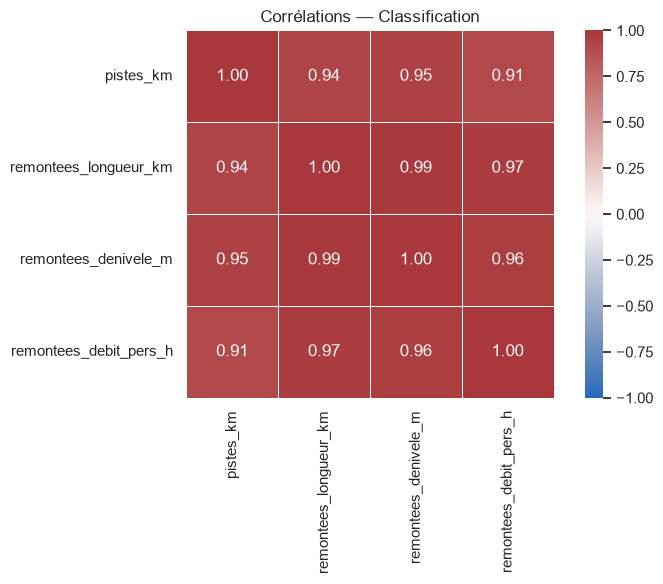

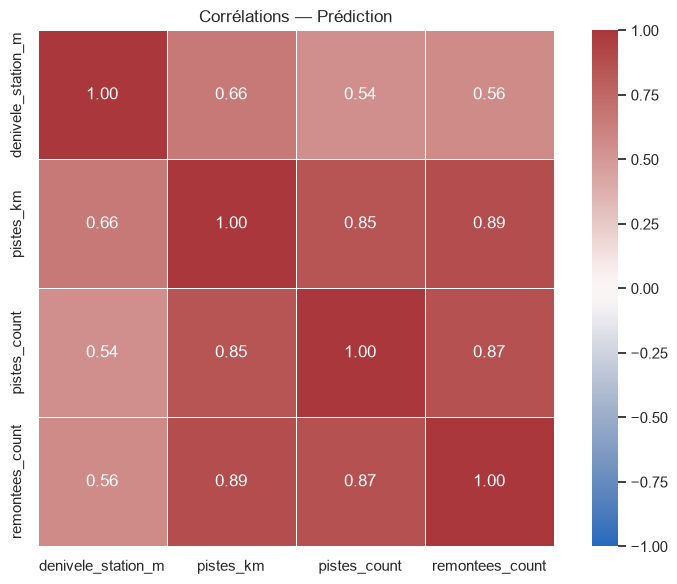

In [8]:
for name, data in datasets.items():
    numeric = data.select_dtypes(include='number')
    correlation = numeric.corr()
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(
        correlation, annot=True, fmt='.2f', cmap='vlag', center=0,
        vmin=-1, vmax=1, square=True, linewidths=.5, ax=ax,
    )
    ax.set_title(f'Corrélations — {name}')
    plt.tight_layout()
    plt.show()

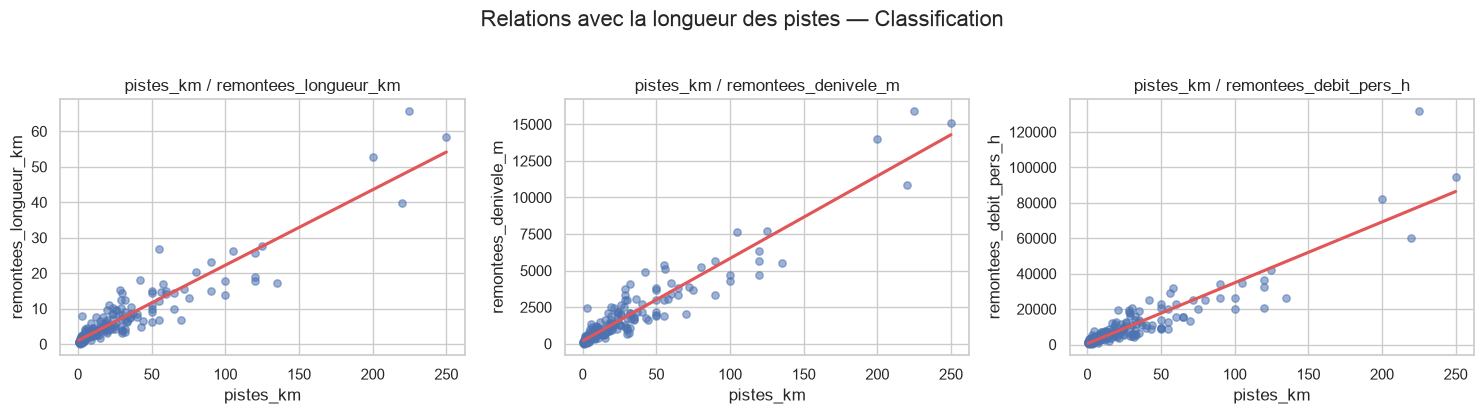

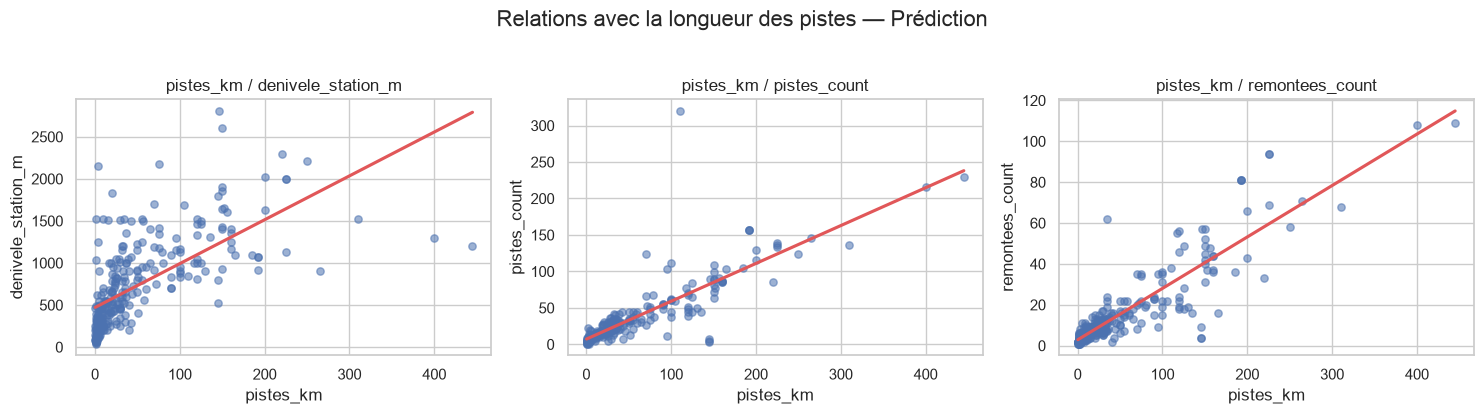

In [9]:
for name, data in datasets.items():
    numeric_columns = data.select_dtypes(include='number').columns.tolist()
    targets = [column for column in numeric_columns if column != 'pistes_km']
    if 'pistes_km' not in data or not targets:
        continue
    fig, axes = plt.subplots(1, len(targets), figsize=(5 * len(targets), 4), squeeze=False)
    for ax, target in zip(axes.flat, targets):
        sns.regplot(
            data=data, x='pistes_km', y=target, ci=None,
            scatter_kws={'alpha': .55, 's': 28},
            line_kws={'color': '#E15759'}, ax=ax,
        )
        ax.set_title(f'pistes_km / {target}')
    fig.suptitle(f'Relations avec la longueur des pistes — {name}', fontsize=16, y=1.03)
    plt.tight_layout()
    plt.show()

## Colonnes catégorielles

Seules les colonnes ayant au plus 20 modalités sont représentées. Les identifiants `station` et `slug`, presque uniques par ligne, restent consultables dans le profil sans produire de graphique peu lisible.

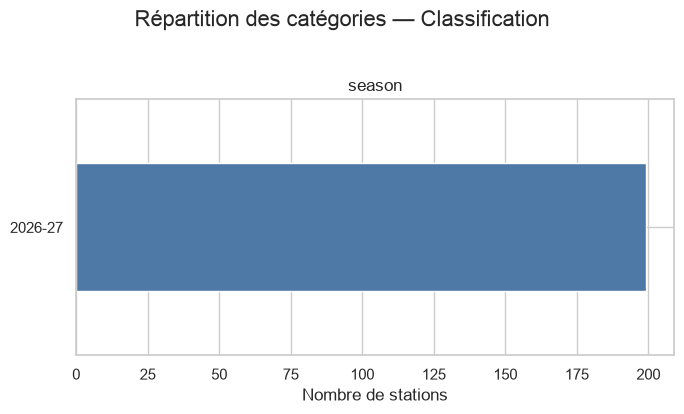

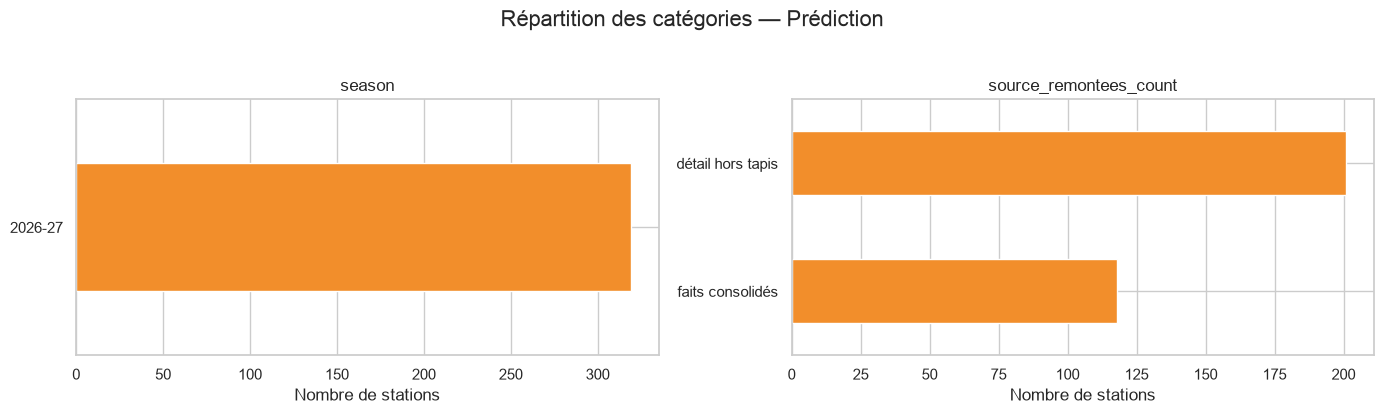

In [10]:
for name, data in datasets.items():
    categorical_columns = [
        column for column in data.select_dtypes(exclude='number').columns
        if data[column].nunique(dropna=False) <= 20
    ]
    if not categorical_columns:
        continue
    fig, axes = plt.subplots(1, len(categorical_columns), figsize=(7 * len(categorical_columns), 4), squeeze=False)
    for ax, column in zip(axes.flat, categorical_columns):
        counts = data[column].fillna('Valeur manquante').astype(str).value_counts().sort_values()
        counts.plot.barh(color=COLORS[name], ax=ax)
        ax.set(title=column, xlabel='Nombre de stations', ylabel='')
    fig.suptitle(f'Répartition des catégories — {name}', fontsize=16, y=1.03)
    plt.tight_layout()
    plt.show()

## Cohérence entre les deux jeux de données

Les CSV partagent les colonnes `station`, `slug`, `season` et `pistes_km`. Cette section vérifie la couverture des identifiants et signale les écarts éventuels sur les valeurs communes.

In [11]:
classification = datasets['Classification']
prediction = datasets['Prédiction']
comparison = classification[['slug', 'station', 'season', 'pistes_km']].merge(
    prediction[['slug', 'station', 'season', 'pistes_km']],
    on='slug', how='outer', suffixes=('_classification', '_prediction'), indicator=True,
)

coverage = comparison['_merge'].value_counts().rename(index={
    'both': 'Présent dans les deux',
    'left_only': 'Classification seulement',
    'right_only': 'Prédiction seulement',
})
display(coverage.to_frame('stations'))

common = comparison.loc[comparison['_merge'] == 'both'].copy()
common['station_identique'] = common['station_classification'].eq(common['station_prediction'])
common['season_identique'] = common['season_classification'].eq(common['season_prediction'])
common['pistes_km_identique'] = np.isclose(
    common['pistes_km_classification'], common['pistes_km_prediction'],
    equal_nan=True,
)
consistency = common[['station_identique', 'season_identique', 'pistes_km_identique']].mean().mul(100).round(1)
display(consistency.rename('cohérence_%').to_frame())

differences = common.loc[
    ~(common['station_identique'] & common['season_identique'] & common['pistes_km_identique'])
]
print(f'{len(differences)} station(s) commune(s) présentent au moins un écart.')
display(differences.drop(columns=['_merge']).head(20))

,stations
_merge,
Présent dans les deux,199
Prédiction seulement,120
Classification seulement,0


,cohérence_%
station_identique,100.0
season_identique,100.0
pistes_km_identique,100.0


0 station(s) commune(s) présentent au moins un écart.


,slug,station_classification,season_classification,pistes_km_classification,station_prediction,season_prediction,pistes_km_prediction,station_identique,season_identique,pistes_km_identique


## À retenir

Après exécution, utilisez le profil de colonnes pour identifier les champs incomplets, les histogrammes et boîtes à moustaches pour détecter les valeurs atypiques, puis les matrices de corrélation pour comprendre quelles mesures évoluent ensemble. La dernière section vérifie que les champs partagés restent cohérents entre les deux étapes du pipeline.